In [1]:
import sys
sys.path.insert(0, '..')

import numpy as np
from matplotlib import pyplot as plt
from tqdm import tqdm
import jax.numpy as jnp
import jax
from scipy.special import erfc, erfcinv
from functools import partial, wraps

from lib import neurons, input_gen, driver, utils

In [8]:
n_trials = 6
ns=200
nd=300
n = 10
rng = jax.random.PRNGKey(12345)

beta=5.85277
b = 2.55
bk =  4.0

hyper = neurons.HyperConfig1(nd=nd, ns=ns, n=n, b=b, bk=bk, beta=beta)
hyperD = neurons.HyperDynConfig1(b=b, bk=bk, beta=beta)
# neuron = neurons.Neuron_Decay_NonInt(hyperparameters=hyper)
# neuron = neurons.Neuron_Decay_Int(hyperparameters=hyper)
neuron = neurons.Neuron_Decay_Int_Variable_n_min1(hyperparameters=hyper)

capa_list = np.zeros((7, n_trials))
rng, subkey = jax.random.split(rng)
for trial_idx in range(n_trials):
    print(f"Trial {trial_idx+1}/{n_trials}")
    for i, coeff in enumerate([1, 2, 4, 8 ,16, 32, 64]):
        if coeff == "infty":
            xs_gen = input_gen.Normal(nd, ns)
        else: 
            xs_gen = input_gen.Normal_Corr_across_Dendrites(nd=nd, ns=ns, coeff=coeff, key=subkey)
        rng, subkey = jax.random.split(rng)
        my_driver = driver.Driver1_bScan(neuron, xs_gen, subkey, hyperD, initial_state=None, resample_every=1000, n_tested_patterns=1000)
        my_driver.run(
                n_init_steps=10000,
                n_steps_phase1=3000,
                n_steps_phase2=20000,
                n_steps_phase3=10000,
                test_every_phase3=50,
                bs=jnp.array([b])
            )
        capa = utils.capacity_numba(my_driver.transient_record, my_driver.steady_record, my_driver.upper99_s)
        print(capa)
        capa_list[i, trial_idx] = capa 

Trial 1/6
[666.]


/tmp/ipykernel_1617789/352387942.py:38: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  capa_list[i, trial_idx] = capa


[755.]
[816.]
[905.]
[800.]
[857.]
[846.5]
Trial 2/6
[634.5]
[752.]
[806.8]
[881.]
[868.]
[835.]
[971.33333333]
Trial 3/6
[582.75]
[655.5]
[823.]
[875.5]
[863.5]
[871.]
[856.]
Trial 4/6
[628.]
[736.33333333]
[862.]
[822.]
[849.33333333]
[856.]
[876.33333333]
Trial 5/6
[626.]
[766.]
[809.]
[848.5]
[841.5]
[879.]
[893.]
Trial 6/6
[670.]
[777.5]
[814.66666667]
[828.]
[856.5]
[928.]
[866.33333333]


In [ ]:
# np.save("../data/fixed_params/capa_vs_coeff/int_variableN_min1_6_trials_params3.npy", capa_list)

In [10]:
capa_list_nonInt = np.load("../data/fixed_params/capa_vs_coeff/nonInt_6_trials_params3.npy")
capa_list_variable_n_min1_int = np.load("../data/fixed_params/capa_vs_coeff/int_variableN_min1_6_trials_params3.npy")
capa_list_int = np.load("../data/fixed_params/capa_vs_coeff/int_6_trials_params3.npy")

In [4]:
capa_list_nonInt.shape
n_trials = 6

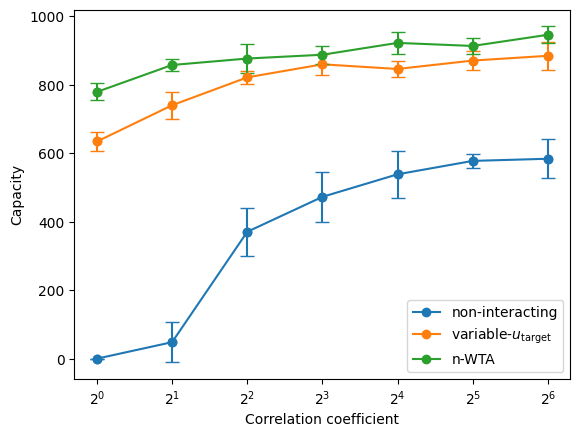

In [ ]:
coeff_list = np.array([1, 2, 4, 8, 16, 32, 64])
plt.plot(coeff_list, np.mean(capa_list_nonInt, axis=1), marker='o', label='non-interacting')
plt.errorbar(coeff_list, np.mean(capa_list_nonInt, axis=1), yerr=np.std(capa_list_nonInt, axis=1), fmt='o', capsize=5, linestyle='None', color='C0')
plt.plot(coeff_list, np.mean(capa_list_variable_n_min1_int, axis=1), marker='o', label=r'variable-$u_{\text{target}}$')
plt.errorbar(coeff_list, np.mean(capa_list_variable_n_min1_int, axis=1), yerr=np.std(capa_list_variable_n_min1_int, axis=1), fmt='o', capsize=5, linestyle='None', color='C1')
plt.plot(coeff_list, np.mean(capa_list_int, axis=1), marker='o', label='n-WTA')
plt.errorbar(coeff_list, np.mean(capa_list_int, axis=1), yerr=np.std(capa_list_int, axis=1), fmt='o', capsize=5, linestyle='None', color='C2')

plt.xscale('log', base=2)
plt.xlabel('Correlation coefficient')
plt.ylabel('Capacity')
plt.legend()

# plt.savefig("../figures/capa_vs_coeff_fixed_params3.png")
plt.show()

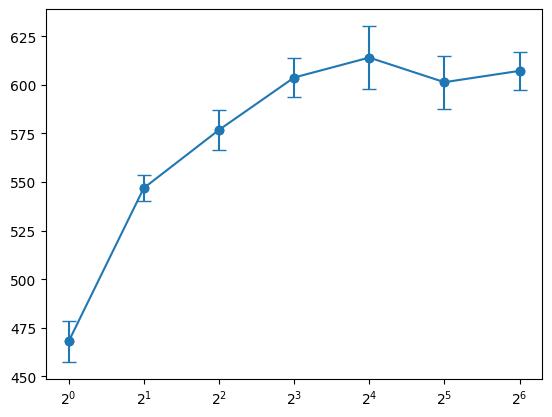

In [20]:
plt.plot(np.array([1, 2, 4, 8, 16, 32, 64]), np.mean(capa_list, axis=1), marker='o')
plt.errorbar(np.array([1, 2, 4, 8, 16, 32, 64]), np.mean(capa_list, axis=1), yerr=np.std(capa_list, axis=1), fmt='o', capsize=5, linestyle='None', color='C0')
plt.xscale('log', base=2)